# 03 · Calibration: learning the twin's parameters from data
**Level: Intermediate** · ~15 min · *Track: Inverse problems*

The open-loop twin of notebook 02 drifted because its **parameters** were wrong. Calibration
(also called *parameter estimation*, *system identification* or the *inverse problem*) finds the
parameters $\theta$ for which the model best explains the sensor data:

$$\hat\theta = \arg\min_\theta \; J(\theta) = \frac{1}{2\sigma^2}\sum_{k,j}\big(y_{k,j} - H u_k(\theta)\big)_j^2$$

**You will learn**
* how to set up and solve a least-squares calibration with SciPy
* how to read the **loss landscape**, and why some parameter pairs are hard to separate (**identifiability**)
* how to attach **uncertainty** to calibrated parameters (Gauss-Newton covariance vs. Monte Carlo)
* how **sensor placement** changes what can be learned

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.optimize import least_squares, minimize_scalar
from dtwin import viz
from dtwin.solvers import Heat1D
from dtwin.sensors import PointSensors, evenly_spaced_1d
viz.set_style()
rng = np.random.default_rng(3)

## 1. Setup: two unknowns
Reality: diffusivity $\alpha^\star=0.012$ and heater power $P^\star = 0.7$ (constant this time).
The twin knows the heater's location and shape but not $\alpha$ or $P$.

In [2]:
NX, DT, NSTEP = 61, 0.05, 200
ALPHA_TRUE, P_TRUE, SIGMA = 0.012, 0.7, 0.01
shape = lambda x: np.exp(-((x - 0.35) / 0.06) ** 2)

def forward(alpha, P, nx=NX):
    m = Heat1D(nx=nx, alpha=alpha, dt=DT)
    return m.x, m.simulate(np.zeros(nx), NSTEP, source=lambda x, t: P * shape(x))

x, (t, U_true) = forward(ALPHA_TRUE, P_TRUE)
sens = PointSensors(evenly_spaced_1d(NX, 6), NX, SIGMA)
Y = sens.observe(U_true, rng)

def residuals(theta, Y=Y, sens=sens):
    alpha, P = theta
    _, (_, U) = forward(alpha, P)
    return ((sens.observe(U) - Y) / SIGMA).ravel()

## 2. One parameter: the loss curve
Fix $P$ at its true value and scan $\alpha$. The cost $J(\alpha)$ has a clean minimum, and
`minimize_scalar` finds it in a few evaluations.

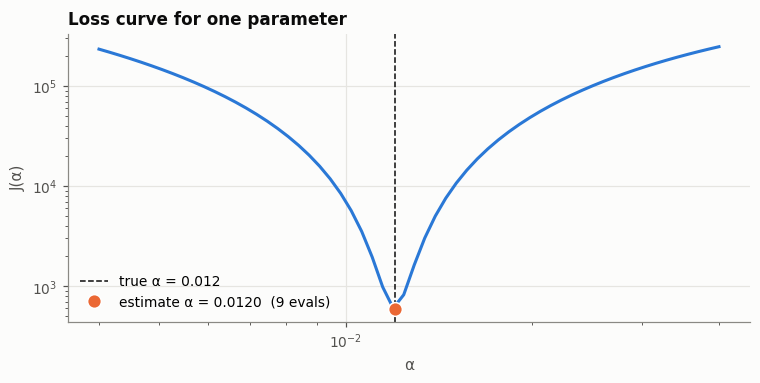

In [3]:
alphas = np.geomspace(0.004, 0.04, 60)
J1 = [0.5 * np.sum(residuals((a, P_TRUE)) ** 2) for a in alphas]
res1 = minimize_scalar(lambda la: 0.5 * np.sum(residuals((np.exp(la), P_TRUE)) ** 2),
                       bounds=np.log([0.004, 0.04]), method="bounded")
a_hat = np.exp(res1.x)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.loglog(alphas, J1, color=viz.TWIN)
ax.axvline(ALPHA_TRUE, color=viz.TRUTH, ls="--", lw=1, label=f"true α = {ALPHA_TRUE}")
ax.plot(a_hat, res1.fun, "o", color=viz.DATA, ms=9, mec="white", label=f"estimate α = {a_hat:.4f}  ({res1.nfev} evals)")
ax.set(xlabel="α", ylabel="J(α)", title="Loss curve for one parameter")
ax.legend()
plt.show()

## 3. Two parameters: the loss landscape
Now both $\alpha$ and $P$ are unknown. The landscape is a **long, tilted valley**: a stronger
heater with faster diffusion produces almost the same sensor readings as a weaker heater with
slower diffusion. The parameters are **correlated**: the data constrain a *combination* of them
far better than each one separately.

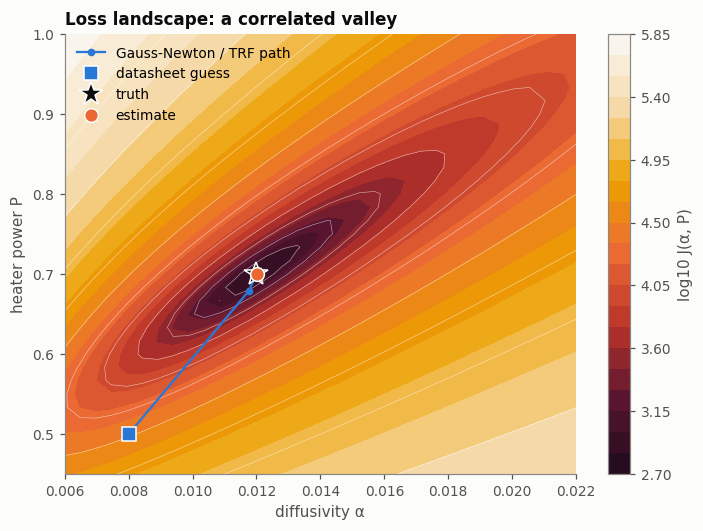

estimate: alpha = 0.01201 (true 0.012),  P = 0.7004 (true 0.7)


In [4]:
A_grid = np.linspace(0.006, 0.022, 34)
P_grid = np.linspace(0.45, 1.0, 34)
J2 = np.array([[0.5 * np.sum(residuals((a, p)) ** 2) for a in A_grid] for p in P_grid])

theta0 = np.array([0.008, 0.5])  # datasheet guess
path = [theta0]
fit = least_squares(residuals, theta0, x_scale=[0.01, 0.5], diff_step=1e-4)
# re-run step by step for the optimisation path (max_nfev grows each time)
for n in range(1, 12):
    r = least_squares(residuals, theta0, x_scale=[0.01, 0.5], diff_step=1e-4, max_nfev=n)
    path.append(r.x)
path = np.array(path)

fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.grid(False)
cs = ax.contourf(A_grid, P_grid, np.log10(J2), levels=25, cmap=viz.FIELD.reversed())
ax.contour(A_grid, P_grid, np.log10(J2), levels=12, colors="white", linewidths=0.4, alpha=0.6)
plt.colorbar(cs, label="log10 J(α, P)")
ax.plot(path[:, 0], path[:, 1], "-o", color=viz.TWIN, ms=4, lw=1.5, label="Gauss-Newton / TRF path")
ax.plot(*theta0, "s", color=viz.TWIN, ms=9, mec="white", label="datasheet guess")
ax.plot(ALPHA_TRUE, P_TRUE, "*", color=viz.INK, ms=16, mec="white", label="truth")
ax.plot(*fit.x, "o", color=viz.DATA, ms=9, mec="white", label="estimate")
ax.set(xlabel="diffusivity α", ylabel="heater power P", title="Loss landscape: a correlated valley")
ax.legend(loc="upper left")
viz.save(fig, "03_landscape.png")
plt.show()
print(f"estimate: alpha = {fit.x[0]:.5f} (true {ALPHA_TRUE}),  P = {fit.x[1]:.4f} (true {P_TRUE})")

## 4. How sure are we? Two ways to get error bars
**Gauss-Newton (Laplace) approximation:** near the optimum the cost is quadratic, so
$\operatorname{Cov}(\hat\theta) \approx (J^\top J)^{-1}$ where $J$ is the Jacobian of the
(σ-scaled) residuals. One calibration gives the full covariance at no extra cost.

**Monte Carlo:** repeat the experiment with fresh noise many times and look at the spread of
estimates. Expensive, but assumption-free. They should agree.

alpha = 0.01201 ± 0.00005   P = 0.7004 ± 0.0013   corr = +0.909


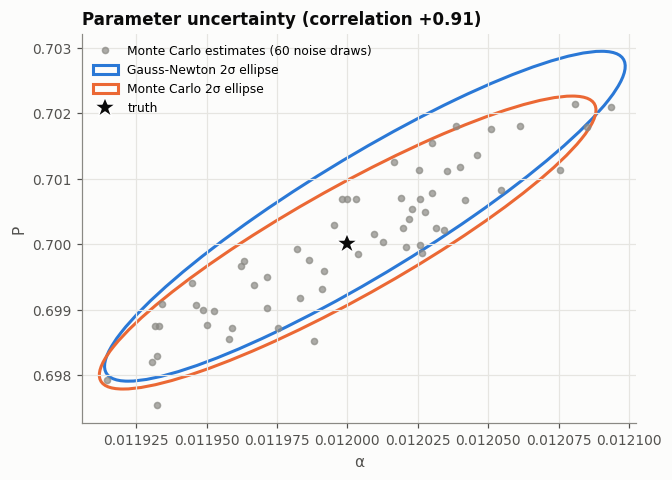

In [5]:
def gn_cov(fit):
    Jac = fit.jac
    return np.linalg.inv(Jac.T @ Jac)

def ellipse(ax, mean, cov, color, label, nsig=2):
    vals, vecs = np.linalg.eigh(cov)
    ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    w, h = 2 * nsig * np.sqrt(vals[::-1])
    ax.add_patch(Ellipse(mean, w, h, angle=ang, fill=False, color=color, lw=2, label=label))

C = gn_cov(fit)
sd = np.sqrt(np.diag(C))
corr = C[0, 1] / (sd[0] * sd[1])
print(f"alpha = {fit.x[0]:.5f} ± {sd[0]:.5f}   P = {fit.x[1]:.4f} ± {sd[1]:.4f}   corr = {corr:+.3f}")

mc = []
for _ in range(60):
    Yb = sens.observe(U_true, rng)
    mc.append(least_squares(lambda th: residuals(th, Yb), fit.x, x_scale=[0.01, 0.5], diff_step=1e-4).x)
mc = np.array(mc)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.plot(mc[:, 0], mc[:, 1], "o", color=viz.MUTED, ms=4, alpha=0.7, label="Monte Carlo estimates (60 noise draws)")
ellipse(ax, fit.x, C, viz.TWIN, "Gauss-Newton 2σ ellipse")
ellipse(ax, mc.mean(0), np.cov(mc.T), viz.DATA, "Monte Carlo 2σ ellipse")
ax.plot(ALPHA_TRUE, P_TRUE, "*", color=viz.INK, ms=15, mec="white", label="truth")
ax.set(xlabel="α", ylabel="P", title=f"Parameter uncertainty (correlation {corr:+.2f})")
ax.legend(fontsize=8)
plt.show()

## 5. Sensor placement decides what is identifiable
Same experiment, three sensor layouts. The ellipse area is the volume of uncertainty: smaller is
better, and its orientation shows *which combination* of parameters the layout cannot pin down.
* **far side**: these sensors only see a diffused, delayed signal, so $\alpha$ is poorly determined
* **2 sensors near the heater**: a long thin ellipse, meaning $\alpha$ and $P$ trade off almost perfectly
* **spread**: sees both the peak and the tails, giving the smallest ellipse

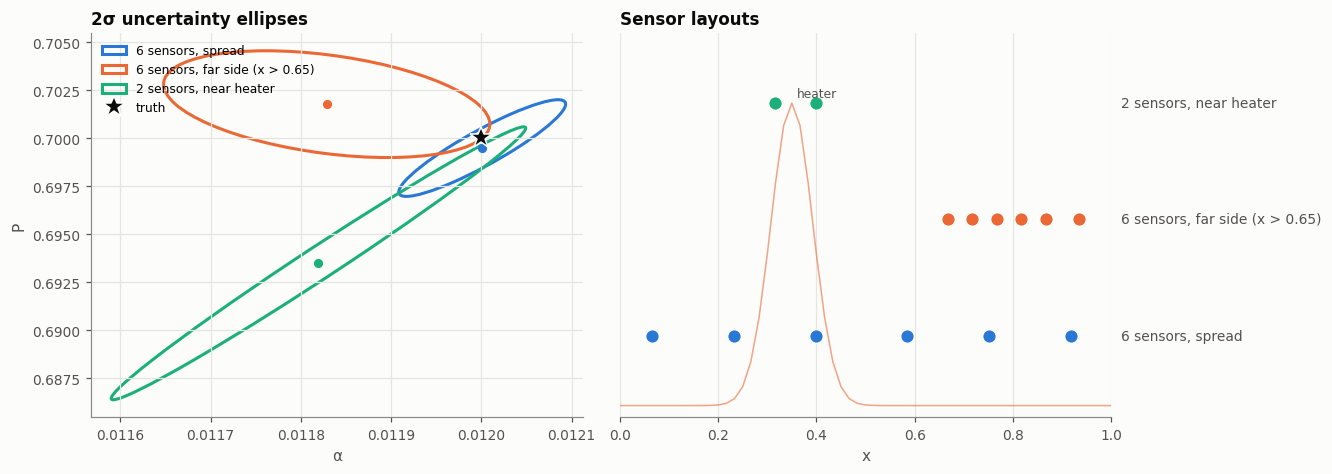

In [6]:
layouts = {
    "6 sensors, spread": evenly_spaced_1d(NX, 6),
    "6 sensors, far side (x > 0.65)": np.linspace(40, 56, 6).astype(int),
    "2 sensors, near heater": np.array([19, 24]),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for i, (name, idx) in enumerate(layouts.items()):
    s = PointSensors(idx, NX, SIGMA)
    Ys = s.observe(U_true, rng)
    f = least_squares(lambda th: residuals(th, Ys, s), [0.01, 0.6], x_scale=[0.01, 0.5], diff_step=1e-4)
    Ci = gn_cov(f)
    ellipse(axes[0], f.x, Ci, viz.SERIES[i], f"{name}")
    axes[0].plot(*f.x, "o", color=viz.SERIES[i], ms=5)
    axes[1].plot(x[idx], np.full(idx.size, i), "o", color=viz.SERIES[i], ms=9, mec="white")
    axes[1].text(1.02, i, name, va="center", fontsize=9, color=viz.INK2)
axes[0].plot(ALPHA_TRUE, P_TRUE, "*", color=viz.INK, ms=15, mec="white", label="truth")
axes[0].autoscale_view()
axes[0].set(xlabel="α", ylabel="P", title="2σ uncertainty ellipses")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].plot(x, 2.6 * shape(x) - 0.6, color=viz.ORANGE, lw=1, alpha=0.6)
axes[1].text(0.36, 2.05, "heater", color=viz.INK2, fontsize=8)
axes[1].set(xlim=(0, 1.0), ylim=(-0.7, 2.6), yticks=[], xlabel="x", title="Sensor layouts")
axes[1].spines["left"].set_visible(False)
plt.show()

## 6. Does calibration close the twin gap?
Calibrate on the first half of the record ($t \le 5$) and **forecast** the second half.
Then break an assumption: the heater power starts drifting at $t=6$. Offline calibration
cannot react to that, which is exactly what online data assimilation (notebook 04) fixes.

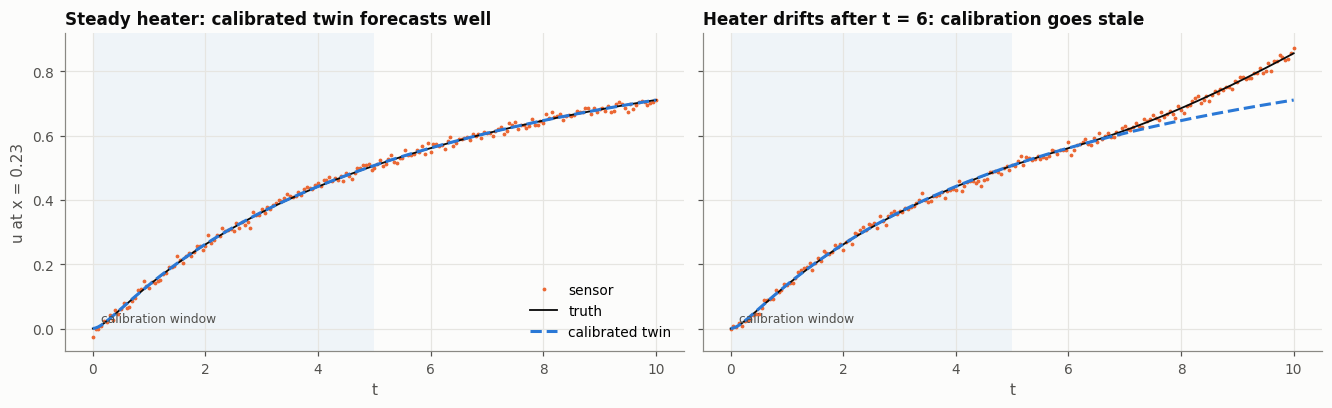

In [7]:
half = t <= 5
def res_half(th):
    _, (_, U) = forward(*th)
    return ((sens.observe(U)[half] - Y[half]) / SIGMA).ravel()

f_half = least_squares(res_half, [0.008, 0.5], x_scale=[0.01, 0.5], diff_step=1e-4)
_, (_, U_cal) = forward(*f_half.x)

drift = lambda tt: P_TRUE * (1 + 0.6 * np.clip(tt - 6, 0, None) / 4)
m = Heat1D(nx=NX, alpha=ALPHA_TRUE, dt=DT)
_, U_drift = m.simulate(np.zeros(NX), NSTEP, source=lambda x, tt: drift(tt) * shape(x))
Y_drift = sens.observe(U_drift, rng)

j = 1
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True, sharey=True)
for ax, Yd, Ud, ttl in [(axes[0], Y, U_true, "Steady heater: calibrated twin forecasts well"),
                        (axes[1], Y_drift, U_drift, "Heater drifts after t = 6: calibration goes stale")]:
    ax.axvspan(0, 5, color=viz.BLUE, alpha=0.06, lw=0)
    ax.text(0.15, 0.02, "calibration window", color=viz.INK2, fontsize=8)
    ax.plot(t, Yd[:, j], ".", color=viz.DATA, ms=3, label="sensor")
    ax.plot(t, Ud[:, sens.idx[j]], color=viz.TRUTH, lw=1.2, label="truth")
    ax.plot(t, U_cal[:, sens.idx[j]], color=viz.TWIN, ls="--", label="calibrated twin")
    ax.set(xlabel="t", title=ttl)
axes[0].set_ylabel(f"u at x = {x[sens.idx[j]]:.2f}")
axes[0].legend()
plt.show()

## Recap
* Calibration is nonlinear least squares; `scipy.optimize.least_squares` does the heavy lifting.
* **Look at the landscape.** Valleys mean correlated parameters; flat directions mean the data cannot see them.
* The Gauss-Newton covariance $(J^\top J)^{-1}$ gives cheap, usually reliable error bars.
* **Experiment design** (where to put sensors) matters as much as the algorithm.
* Offline calibration assumes the parameters are constant. Real assets drift, so the twin must
  keep learning while running → **04 Kalman filter**.

**Exercises**
1. Add the heater *position* as a third unknown. Which pairs become correlated?
2. Double the noise. How do the ellipse axes scale? (Theory: linearly in σ.)